# 10. Chemical physics: Kramers' escape rate

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 6

Chemical reactions, the unfolding of a protein, the switching of a magnetic bit and the
nucleation of a bubble all have the same structure: a system sits in a potential well
and, now and then, thermal noise carries it over a barrier much higher than $k_BT$.
The rate is controlled by the Arrhenius factor $e^{-\Delta U/k_BT}$, and the prefactor
is what Kramers (1940) computed. For a Brownian particle in the overdamped limit the
mean escape time is an exact double integral; for a high barrier both integrals are
dominated by a single point, and Laplace's method (Chapter 6) turns the double
integral into Kramers' formula. The small parameter is $k_BT/\Delta U$. This chapter
checks the formula and its first correction against the exact integral and against a
simulation.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()

## 10.1 The exact mean escape time

An overdamped particle with friction coefficient $\zeta$ in a potential $U(x)$ obeys
the Langevin equation $\zeta\dot x = -U'(x) + \xi(t)$, with diffusion coefficient
$D = k_BT/\zeta$. The mean time to reach a point $c$ beyond the barrier, starting from
$x_0$ in the well, satisfies a second-order ODE whose solution is

$$ \tau = \frac1D\int_{x_0}^{c}\mathrm dy\; e^{\beta U(y)}\int_{-\infty}^{y}\mathrm dz\;
   e^{-\beta U(z)} , \qquad \beta = 1/k_BT . $$

We take the cubic potential $U(x) = \Delta U\,(3x^2 - 2x^3)$, with its minimum at
$x = 0$, its barrier top at $x = 1$ and barrier height $\Delta U$; lengths are in units
of the distance $L$ from the well to the barrier, and times in units of $L^2/D$. The single
parameter is the barrier height in units of the thermal energy,

$$ \lambda = \frac{\Delta U}{k_BT} , \qquad
   \tau = \int_0^2\mathrm dy\; e^{\lambda u(y)}\int_{-\infty}^{y}\mathrm dz\; e^{-\lambda u(z)} ,
   \qquad u(x) = 3x^2 - 2x^3 . $$

The integrals are done numerically. For large $\lambda$, $\tau$ grows like $e^{\lambda}$,
so the outer integrand is scaled by $e^{-\lambda}$ to keep the numbers in range.

In [2]:
def u(x):
    return 3 * x**2 - 2 * x**3


def tau_exact(lam, c=2.0):
    """Mean first-passage time from the bottom of the well (x = 0) to x = c."""
    def inner(y):
        return quad(lambda z: math.exp(-lam * u(z)), -1.5, y, points=[0] if y > 0 else None,
                    epsabs=0, epsrel=1e-13, limit=200)[0]
    scaled = quad(lambda y: math.exp(lam * (u(y) - 1)) * inner(y), 0, c, points=[1],
                  epsabs=0, epsrel=1e-12, limit=200)[0]
    return scaled * math.exp(lam)


lams = np.logspace(math.log10(2), math.log10(40), 18)
tau = np.array([tau_exact(l) for l in lams])
for l in (2, 5, 10, 20, 40):
    print(f"lambda = {l:2d}: tau = {tau_exact(l):.6g}")

lambda =  2: tau = 4.40659
lambda =  5: tau = 33.4112
lambda = 10: tau = 2380.27
lambda = 20: tau = 2.57786e+07
lambda = 40: tau = 6.20645e+15


## 10.2 Two Laplace integrals

For large $\lambda$ the inner integrand $e^{-\lambda u(z)}$ is sharply peaked at the
bottom of the well, $z = 0$; once $y$ is past the well the inner integral is the whole
Gaussian, $\int e^{-\lambda u}\,\mathrm dz \approx \sqrt{2\pi/(\lambda u''(0))}$. The
outer integrand $e^{\lambda u(y)}$ is sharply peaked at the barrier top, $y = 1$, where
the inner integral has already reached that value. Each is a Laplace integral, so

$$ \tau \approx \sqrt{\frac{2\pi}{\lambda u''(0)}}\;
   e^{\lambda}\sqrt{\frac{2\pi}{\lambda |u''(1)|}}
   = \frac{2\pi}{\lambda\sqrt{u''(0)\,|u''(1)|}}\,e^{\lambda} = \frac{\pi}{3\lambda}e^{\lambda} . $$

In dimensional form this is Kramers' result for the escape rate in the overdamped
(high-friction) limit,

$$ k = \frac1\tau = \frac{\sqrt{U''(x_\mathrm{min})\,|U''(x_\mathrm{max})|}}{2\pi\zeta}\,
   e^{-\Delta U/k_BT} . $$

The prefactor contains only the curvatures at the two special points: the shape of the
potential elsewhere enters only through corrections in $k_BT/\Delta U$. The first of
these follows from the corrected Laplace formula of Chapter 6, which needs the third
and fourth derivatives at the peak. For the cubic potential $u''' = -12$ and
$u'''' = 0$ at both points, and each integral acquires a factor $1 + 5/(36\lambda)$.
`asymp.laplace_method` evaluates both.

In [3]:
def tau_kramers(lam, correction):
    well = am.laplace_method(lam, f0=0.0, f2=-6.0, f3=12.0, g0=1.0, correction=correction)
    barrier = am.laplace_method(lam, f0=1.0, f2=-6.0, f3=-12.0, g0=1.0, correction=correction)
    return well * barrier


tk0 = np.array([tau_kramers(l, False) for l in lams])
tk1 = np.array([tau_kramers(l, True) for l in lams])
err0 = np.abs(tk0 / tau - 1)
err1 = np.abs(tk1 / tau - 1)
for name, e in (("Kramers", err0), ("with first correction", err1)):
    s, p = am.loglog_slope(lams, e, fit_range=(10, 40))
    print(f"{name:22s}: relative error ~ {p:.3g} lambda^{s:.2f}")
for l in (2, 5, 10, 20):
    t = tau_exact(l)
    print(f"lambda = {l:2d}: Kramers {tau_kramers(l, False) / t - 1:+.4f}, corrected {tau_kramers(l, True) / t - 1:+.5f}")

Kramers               : relative error ~ 0.347 lambda^-1.06
with first correction : relative error ~ 0.506 lambda^-2.14
lambda =  2: Kramers -0.1220, corrected +0.00416
lambda =  5: Kramers -0.0697, corrected -0.01726
lambda = 10: Kramers -0.0309, corrected -0.00384
lambda = 20: Kramers -0.0146, corrected -0.00083


The leading formula is 12 % low at $\lambda = 2$, 3 % low at a barrier of
$10\,k_BT$ and 0.7 % low at $40\,k_BT$; its error falls roughly like $1/\lambda$, as
expected. With the first correction the error falls roughly like $1/\lambda^2$ and is below
0.4 % at $10\,k_BT$. For most chemical barriers ($\lambda$ of 10 to 40) the leading
formula is accurate to a few per cent, far better than the rate constants it is
usually compared with.

## 10.3 A simulation

The double integral is exact, but it is worth checking against the process it
describes. We integrate the dimensionless Langevin equation
$\mathrm dx = -\lambda u'(x)\,\mathrm dt + \sqrt2\,\mathrm dW$ for many particles started
at $x = 0$, with the Euler–Maruyama scheme, and record when each first reaches $x = 2$.

In [4]:
def simulate(lam, n=2000, dt=2e-3, seed=0):
    rng = np.random.default_rng(seed)
    x = np.zeros(n)
    alive = np.arange(n)
    t_exit = np.zeros(n)
    t = 0.0
    while alive.size:
        xa = x[alive]
        xa += -lam * 6 * xa * (1 - xa) * dt + math.sqrt(2 * dt) * rng.standard_normal(xa.size)
        x[alive] = xa
        t += dt
        out = xa >= 2.0
        t_exit[alive[out]] = t
        alive = alive[~out]
    return t_exit


sim_lams = (2, 3, 4, 5, 6)
sims = {l: simulate(l, seed=l) for l in sim_lams}
for l in sim_lams:
    T = sims[l]
    print(f"lambda = {l}: simulated tau = {T.mean():.2f} +/- {T.std() / math.sqrt(T.size):.2f};"
          f" exact {tau_exact(l):.2f}; std/mean = {T.std() / T.mean():.2f}")

lambda = 2: simulated tau = 4.27 +/- 0.09; exact 4.41; std/mean = 0.93
lambda = 3: simulated tau = 8.07 +/- 0.17; exact 7.87; std/mean = 0.96
lambda = 4: simulated tau = 15.58 +/- 0.36; exact 15.66; std/mean = 1.04
lambda = 5: simulated tau = 32.88 +/- 0.74; exact 33.41; std/mean = 1.00
lambda = 6: simulated tau = 75.15 +/- 1.66; exact 74.63; std/mean = 0.99


The simulated mean escape times agree with the double integral within one or two
standard errors (about 2 % for 2000 particles). The standard deviation of the
escape times is close to the mean, the signature of an exponential distribution:
the particle forgets how long it has waited, and escape is a Poisson process with rate
$1/\tau$. This memoryless behaviour, which panel (d) shows directly, is what makes a
rate constant a meaningful quantity; it holds when the barrier is high enough that
the particle equilibrates in the well long before it escapes. At $\lambda = 2$ that
separation of time scales is weak, and the distribution is visibly not exponential.

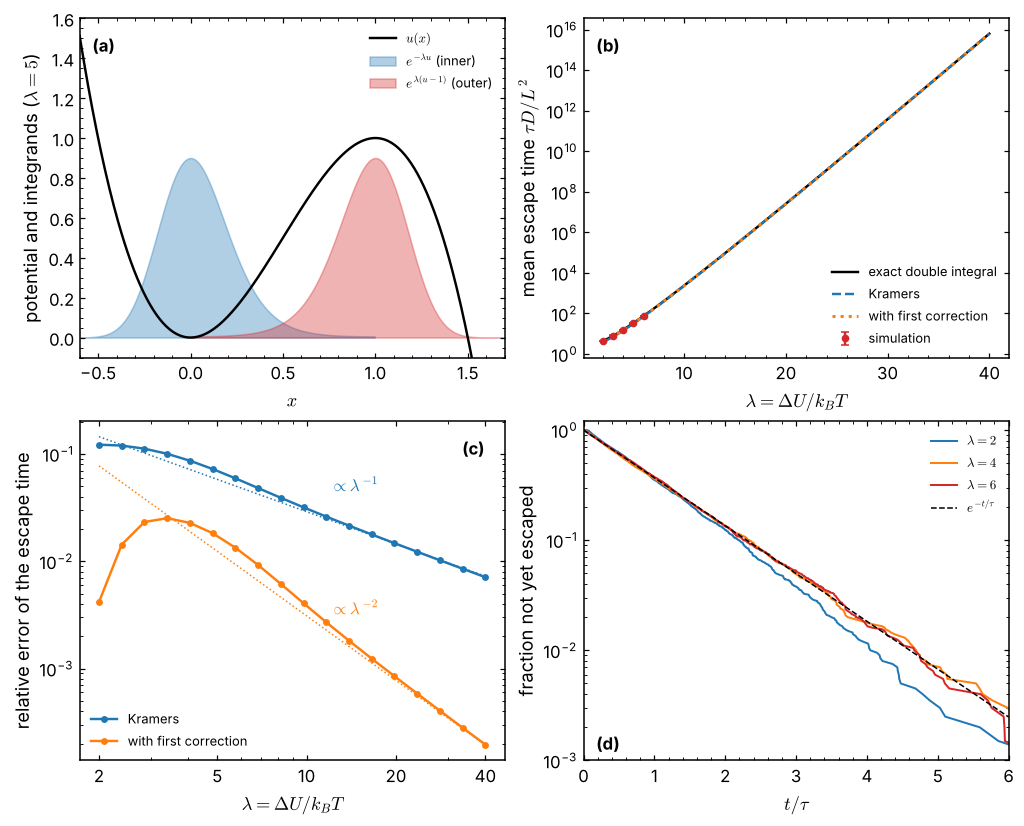

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
xs = np.linspace(-0.6, 1.7, 400)
lam_show = 5
ax.plot(xs, u(xs), "k", lw=1.6, label="$u(x)$")
xi, xo = xs[xs <= 1.0], xs[xs >= 0.0]
ax.fill_between(xi, 0, 0.9 * np.exp(-lam_show * u(xi)), color="C0", alpha=0.35,
                label=r"$e^{-\lambda u}$ (inner)")
ax.fill_between(xo, 0, 0.9 * np.exp(lam_show * (u(xo) - 1)), color="C3", alpha=0.35,
                label=r"$e^{\lambda (u - 1)}$ (outer)")
ax.set_xlim(-0.6, 1.7); ax.set_ylim(-0.1, 1.6)
ax.set_xlabel("$x$"); ax.set_ylabel("potential and integrands ($\\lambda = 5$)")
ax.legend(loc="upper right", fontsize=8.5); am.panel_label(ax, "(a)")

ax = axes[0, 1]
ax.semilogy(lams, tau, "k", lw=1.6, label="exact double integral")
ax.semilogy(lams, tk0, "C0--", label="Kramers")
ax.semilogy(lams, tk1, "C1:", lw=2, label="with first correction")
m = np.array([sims[l].mean() for l in sim_lams])
e = np.array([sims[l].std() / math.sqrt(sims[l].size) for l in sim_lams])
ax.errorbar(sim_lams, m, yerr=e, fmt="o", color="C3", ms=4, label="simulation")
ax.set_xlabel(r"$\lambda = \Delta U/k_BT$"); ax.set_ylabel(r"mean escape time $\tau D/L^2$")
ax.legend(loc="lower right", fontsize=8.5); am.panel_label(ax, "(b)")

ax = axes[1, 0]
ax.loglog(lams, err0, "o-", ms=3.5, color="C0", label="Kramers")
ax.loglog(lams, err1, "o-", ms=3.5, color="C1", label="with first correction")
ax.loglog(lams, 0.29 / lams, "C0:", lw=1)
ax.loglog(lams, 0.31 / lams**2, "C1:", lw=1)
ax.text(12, 0.045, r"$\propto\lambda^{-1}$", color="C0")
ax.text(12, 3.2e-3, r"$\propto\lambda^{-2}$", color="C1")
ax.set_xlabel(r"$\lambda = \Delta U/k_BT$"); ax.set_ylabel("relative error of the escape time")
ax.set_xticks([2, 5, 10, 20, 40]); ax.set_xticklabels(["2", "5", "10", "20", "40"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.legend(loc="lower left", fontsize=8.5); am.panel_label(ax, "(c)", x=0.9)

ax = axes[1, 1]
for l, c in zip((2, 4, 6), ("C0", "C1", "C3")):
    T = np.sort(sims[l]) / tau_exact(l)
    surv = 1 - np.arange(1, T.size + 1) / T.size
    ax.semilogy(T, np.maximum(surv, 1e-4), color=c, lw=1.3, label=rf"$\lambda = {l}$")
tt = np.linspace(0, 6, 50)
ax.semilogy(tt, np.exp(-tt), "k--", lw=1, label=r"$e^{-t/\tau}$")
ax.set_xlim(0, 6); ax.set_ylim(1e-3, 1.2)
ax.set_xlabel(r"$t/\tau$"); ax.set_ylabel("fraction not yet escaped")
ax.legend(loc="upper right", fontsize=8.5); am.panel_label(ax, "(d)", y=0.08)
plt.show()

**(a)** The cubic potential and the two integrands at $\lambda = 5$: the inner one is
concentrated in the well, the outer one at the barrier top (each shown over the part
of its range of integration that matters). **(b)** Mean escape time:
the exact double integral, Kramers' formula, the formula with its first correction,
and Brownian-dynamics simulations (2000 particles each). **(c)** Relative errors of
the asymptotic formulas, with $1/\lambda$ and $1/\lambda^2$ guides; the dip of the
corrected curve near $\lambda = 2$ is where its error changes sign. **(d)** Fraction of
simulated particles that have not escaped by time $t$, against $e^{-t/\tau}$.

## Summary

* The mean escape time over a barrier is an exact double integral; for a barrier high
  compared with $k_BT$ it is a product of two Laplace integrals, one at the bottom of
  the well and one at the top of the barrier.
* The result is Kramers' formula: Arrhenius factor times a prefactor that depends only
  on the two curvatures. Its relative error is of order $k_BT/\Delta U$.
* The corrected Laplace formula gives the next term; for the cubic potential the error
  then falls like $(k_BT/\Delta U)^2$.
* Escape is a Poisson process when the barrier is high, which is why a single rate
  constant describes it.

## Suggested references

* C. W. Gardiner, *Stochastic Methods: A Handbook for the Natural and Social
  Sciences*, 4th ed. (Springer, 2009).
* H. Risken, *The Fokker–Planck Equation*, 2nd ed. (Springer, 1989).
* N. G. van Kampen, *Stochastic Processes in Physics and Chemistry*, 3rd ed.
  (North-Holland, 2007).
* H. A. Kramers, "Brownian motion in a field of force and the diffusion model of
  chemical reactions", *Physica* **7**, 284 (1940).
* P. Hänggi, P. Talkner and M. Borkovec, "Reaction-rate theory: fifty years after
  Kramers", *Rev. Mod. Phys.* **62**, 251 (1990).

## Exercises

1. Derive the double-integral formula for $\tau$ from the backward equation
   $D\,e^{\beta U}(e^{-\beta U}\tau')' = -1$ with $\tau(c) = 0$ and $\tau'(-\infty) = 0$.
2. Show that each Laplace integral for the cubic potential acquires the factor
   $1 + 5/(36\lambda)$, and find the correction for the double well
   $U = \Delta U(1 - x^2)^2$ escaping from $x = -1$ over $x = 0$.
3. Show that $\tau$ is almost independent of the starting point $x_0$ and of the
   end point $c$, as long as $x_0$ is in the well and $c$ is beyond the barrier.
   Estimate the size of the dependence.
4. Reduce the time step in the simulation and estimate the bias of the Euler–Maruyama
   scheme in the mean escape time.

---

**Previous:** [9. Sums: Euler–Maclaurin and the Stirling series](../part2_integrals_and_sums/09_sums_euler_maclaurin_and_stirling.ipynb) &nbsp;·&nbsp; **Next:** [11. Heat transfer: transient conduction at short and long times](11_transient_heat_conduction.ipynb)